# 🎓 Who's Who in the Classroom?
## Discovering Student Personas with K-Means & the Elbow Method

Every class has them: the genius who never opens a book, the student who studies all day,
and everyone in between. Can a machine find these **student personas** using only two numbers?

**Features:** 📚 `Study_Hours` (per week) and 🧠 `IQ`
**Dataset:** 260 students at the fictional *Hogsfield Academy*
**Algorithm:** K-Means, with the **Elbow Method** to pick the number of clusters

### The hidden personas (the model never sees these labels)
| Persona | Study Hours | IQ | Description |
|---|---|---|---|
| 😎 Gifted Slackers | very low (~5) | high (~132) | Naturally smart, barely study |
| 💪 Hardworking Grinders | very high (~38) | average (~100) | Make up for it with pure effort |
| ⚖️ Balanced Students | moderate (~20) | above avg (~112) | Steady and consistent |
| 🚀 Genius Overachievers | high (~36) | very high (~138) | Smart *and* study hard |
| 😴 Disengaged Students | very low (~6) | below avg (~92) | Need some motivation |

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(7)   # fixed seed so results are reproducible

## 2. Create the Hogsfield Academy Dataset
Each persona is generated with its own average and spread for study hours and IQ.

In [2]:
# persona: (number of students, hours mean, hours spread, IQ mean, IQ spread)
personas = {
    "Gifted Slackers":      (50,  5, 2.5, 132, 6),
    "Hardworking Grinders": (60, 38, 4.0, 100, 6),
    "Balanced Students":    (65, 20, 3.5, 112, 5),
    "Genius Overachievers": (40, 36, 3.5, 138, 5),
    "Disengaged Students":  (45,  6, 2.5,  92, 6),
}

first_names = ["Aarav", "Zara", "Leo", "Maya", "Omar", "Ivy", "Kai", "Noor", "Ethan", "Lila",
               "Rohan", "Sofia", "Yusuf", "Ava", "Arjun", "Mia", "Hassan", "Chloe", "Ravi", "Emma"]

rows = []
for persona, (n, h_mean, h_sd, iq_mean, iq_sd) in personas.items():
    for _ in range(n):
        rows.append({
            "Student": f"{rng.choice(first_names)}_{rng.integers(100, 999)}",
            "Study_Hours": round(float(np.clip(rng.normal(h_mean, h_sd), 0, 50)), 1),
            "IQ": int(round(rng.normal(iq_mean, iq_sd))),
            "True_Persona": persona,   # hidden label, used only to check results at the end
        })

df = pd.DataFrame(rows).sample(frac=1, random_state=1).reset_index(drop=True)  # shuffle

print("Total students:", len(df))
df.head(10)

Total students: 260


,Student,Study_Hours,IQ,True_Persona
0,Kai_477,35.5,110,Hardworking Grinders
1,Mia_774,1.5,87,Disengaged Students
2,Noor_650,33.8,144,Genius Overachievers
3,Emma_552,25.2,117,Balanced Students
4,Aarav_696,30.7,141,Genius Overachievers
5,Arjun_156,3.9,93,Disengaged Students
6,Kai_124,39.4,112,Hardworking Grinders
7,Mia_941,5.5,98,Disengaged Students
8,Emma_159,17.3,106,Balanced Students
9,Kai_740,41.5,95,Hardworking Grinders


In [3]:
df[["Study_Hours", "IQ"]].describe().round(2)

,Study_Hours,IQ
count,260.00,260.00
mean,21.20,113.35
std,13.92,17.29
min,0.20,83.00
25%,6.85,99.00
50%,19.85,110.00
75%,35.60,131.00
max,43.80,147.00


## 3. Look at the Raw Data
This is what the model sees: just dots, with no labels. The dashed lines mark the average study hours and the average IQ (100).

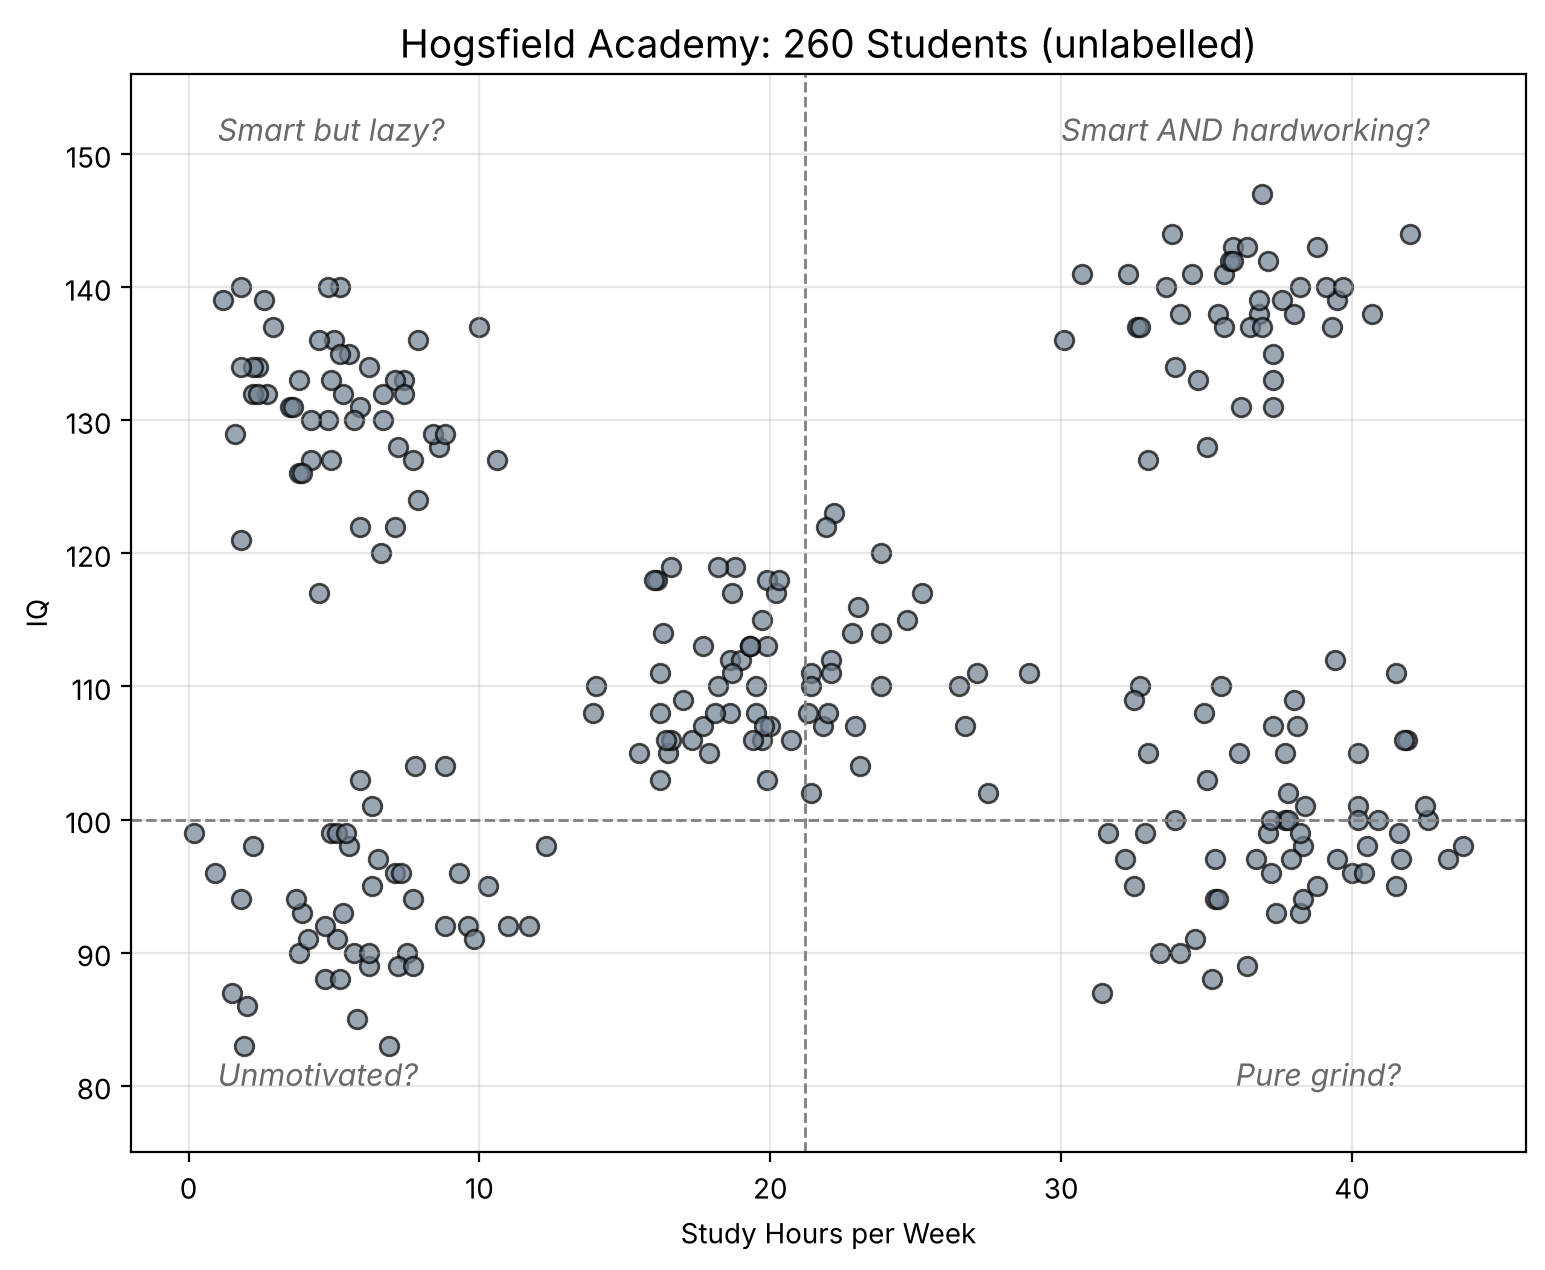

In [4]:
plt.figure(figsize=(9, 7))
plt.scatter(df["Study_Hours"], df["IQ"], color="slategray", alpha=0.7, edgecolors="k", s=45)

plt.axvline(df["Study_Hours"].mean(), color="gray", ls="--", lw=1)
plt.axhline(100, color="gray", ls="--", lw=1)
plt.text(1, 151, "Smart but lazy?", fontsize=11, style="italic", color="dimgray")
plt.text(30, 151, "Smart AND hardworking?", fontsize=11, style="italic", color="dimgray")
plt.text(1, 80, "Unmotivated?", fontsize=11, style="italic", color="dimgray")
plt.text(36, 80, "Pure grind?", fontsize=11, style="italic", color="dimgray")

plt.title("Hogsfield Academy: 260 Students (unlabelled)", fontsize=14)
plt.xlabel("Study Hours per Week")
plt.ylabel("IQ")
plt.ylim(75, 156)
plt.grid(alpha=0.3)
plt.show()

## 4. Scale the Features
Study Hours range from about 0 to 48, while IQ ranges from about 80 to 150. K-Means groups points by distance,
so we standardise both features. Otherwise IQ would dominate.

In [5]:
X = df[["Study_Hours", "IQ"]].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data (first 5 rows):")
print(X_scaled[:5].round(3))

Scaled data (first 5 rows):
[[ 1.029 -0.194]
 [-1.418 -1.527]
 [ 0.907  1.777]
 [ 0.288  0.212]
 [ 0.683  1.603]]


## 5. The Elbow Method: Calculating WCSS
**WCSS (Within-Cluster Sum of Squares)** measures how tightly packed each cluster is:
the sum of squared distances from every student to their cluster centre.

- Adding more clusters always lowers WCSS.
- The **elbow** is the point where the curve suddenly flattens. Beyond it, extra clusters add little value.

We train K-Means for K = 1 to 10 and record WCSS each time.

In [6]:
k_values = range(1, 11)
wcss = []

for k in k_values:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)          # inertia_ = WCSS

wcss_table = pd.DataFrame({
    "K": list(k_values),
    "WCSS": np.round(wcss, 2),
    "Drop from previous K": ["-"] + list(np.round(-np.diff(wcss), 2)),
})
wcss_table

,K,WCSS,Drop from previous K
0,1,520.00,-
1,2,307.58,212.42
2,3,188.30,119.28
3,4,89.07,99.23
4,5,35.25,53.82
5,6,30.53,4.72
6,7,26.49,4.04
7,8,23.43,3.06
8,9,20.75,2.67
9,10,18.57,2.18


### Finding the elbow
Look at the **"Drop from previous K"** column. The drops are large at first, then they suddenly become tiny.
Simple rule: **the elbow is the last K before adding one more cluster reduces WCSS by less than 5% of the starting WCSS.**

In [7]:
threshold = 0.05 * wcss[0]          # 5% of WCSS at K=1
drops = -np.diff(wcss)               # drops[i] = WCSS(K=i+1) - WCSS(K=i+2)

best_k = int(np.argmax(drops < threshold)) + 1   # first K where the next drop is small
print(f"Threshold for a 'small' drop: {threshold:.1f}")
print(f"Going from K={best_k} to K={best_k+1} only reduces WCSS by {drops[best_k-1]:.1f}")
print(f"\nOptimal number of clusters (elbow): K = {best_k}")

Threshold for a 'small' drop: 26.0
Going from K=5 to K=6 only reduces WCSS by 4.7

Optimal number of clusters (elbow): K = 5


## 6. Elbow Method Visualisation

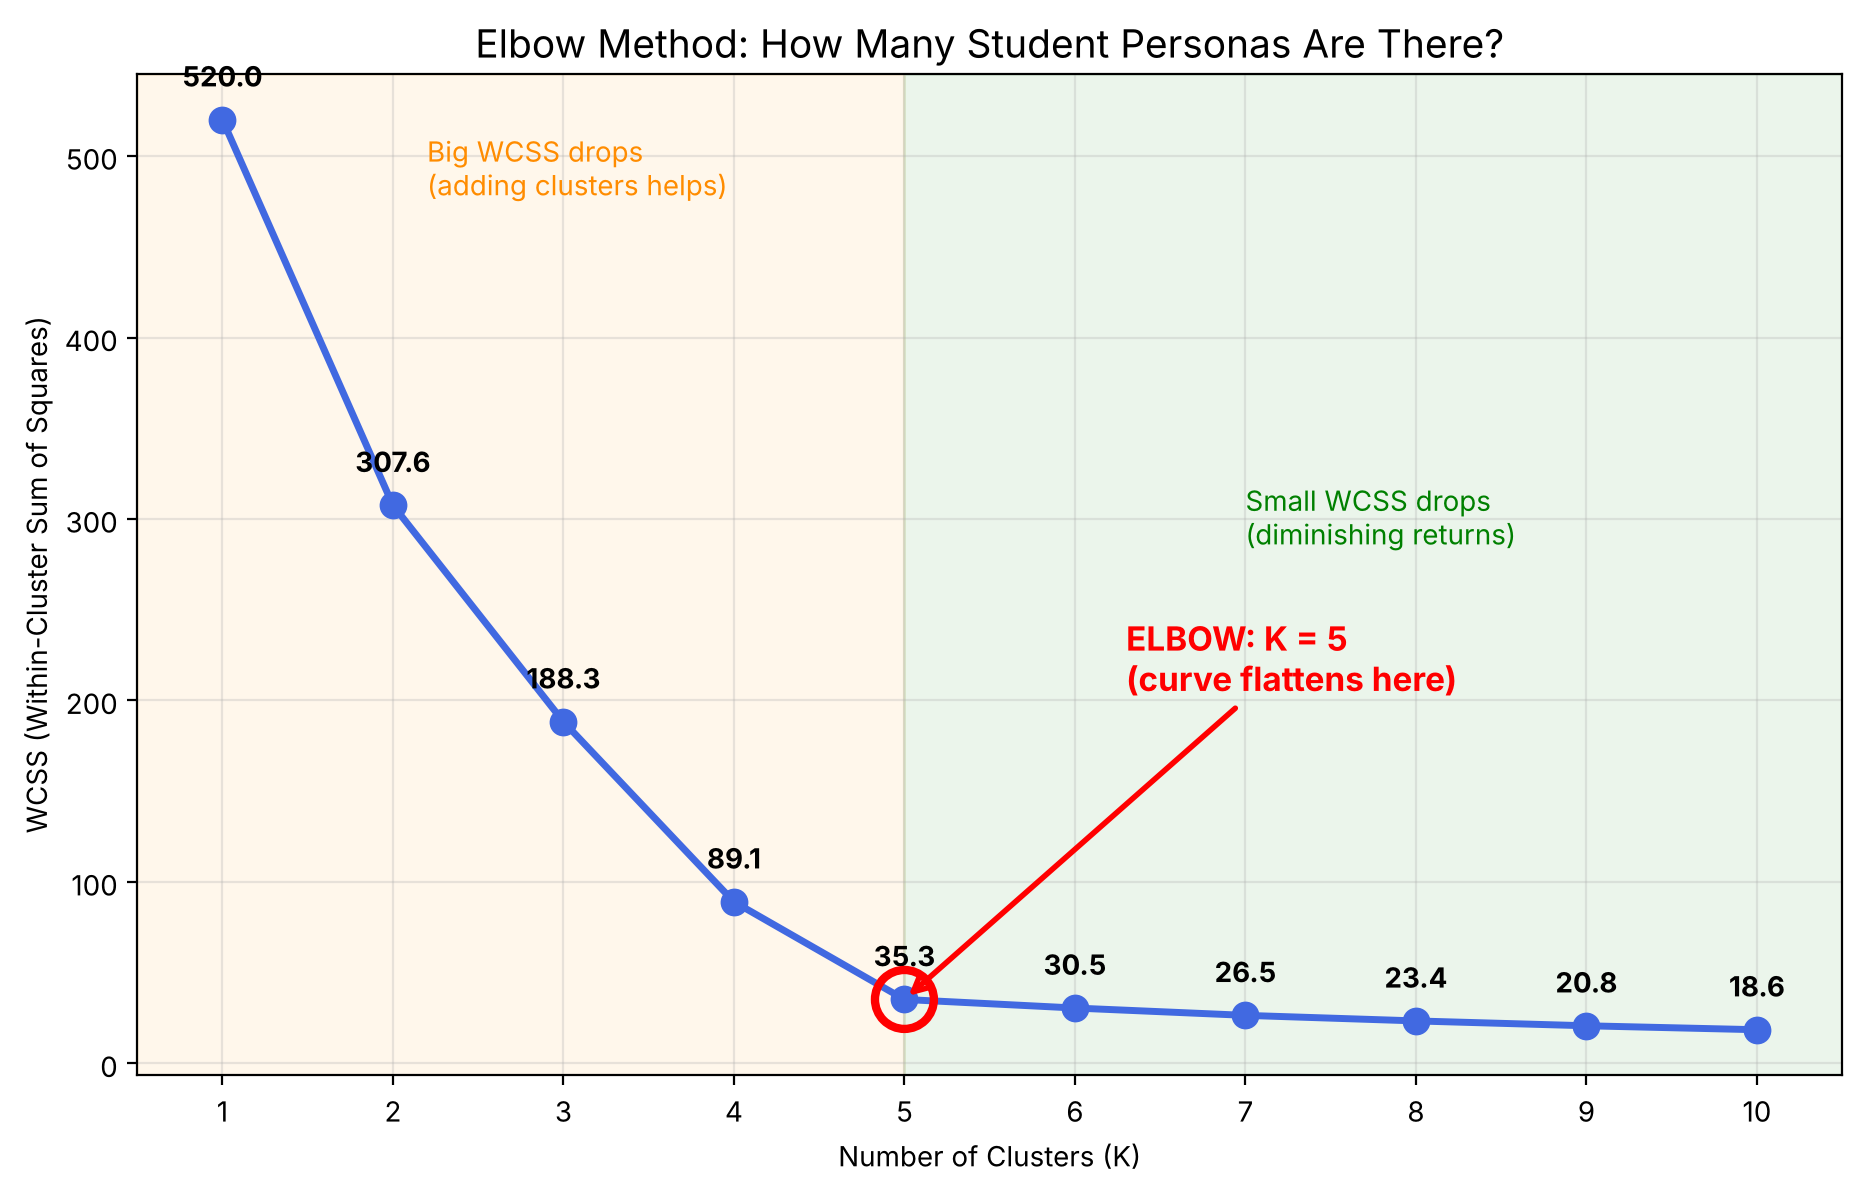

In [8]:
fig, ax = plt.subplots(figsize=(11, 6.5))

ax.plot(k_values, wcss, marker="o", color="royalblue", lw=2.5, ms=9, zorder=3)

# WCSS value on every point
for k, w in zip(k_values, wcss):
    ax.annotate(f"{w:.1f}", (k, w), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=10, fontweight="bold")

# highlight the elbow
ax.scatter(best_k, wcss[best_k - 1], s=450, facecolors="none", edgecolors="red", lw=3, zorder=4)
ax.annotate(f"ELBOW: K = {best_k}\n(curve flattens here)", (best_k, wcss[best_k - 1]),
            xytext=(best_k + 1.3, wcss[best_k - 1] + 170),
            arrowprops=dict(arrowstyle="->", color="red", lw=2),
            color="red", fontsize=12, fontweight="bold")

# shade the "steep" and "flat" zones
ax.axvspan(0.5, best_k, color="orange", alpha=0.08)
ax.axvspan(best_k, 10.5, color="green", alpha=0.08)
ax.text(2.2, max(wcss) * 0.92, "Big WCSS drops\n(adding clusters helps)", fontsize=10, color="darkorange")
ax.text(7, max(wcss) * 0.55, "Small WCSS drops\n(diminishing returns)", fontsize=10, color="green")

ax.set_title("Elbow Method: How Many Student Personas Are There?", fontsize=14)
ax.set_xlabel("Number of Clusters (K)")
ax.set_ylabel("WCSS (Within-Cluster Sum of Squares)")
ax.set_xticks(list(k_values))
ax.set_xlim(0.5, 10.5)
ax.grid(alpha=0.3)
plt.show()

**Interpretation:** WCSS falls steeply up to **K = 5**. After that, each extra cluster removes only a few units.
The algorithm found **5 groups**, exactly the number of personas we hid in the data. 🎯

## 7. Train the Final K-Means Model

In [9]:
kmeans = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# centroids back in real units (hours, IQ)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
print("Final WCSS:", round(kmeans.inertia_, 2))
pd.DataFrame(centroids, columns=["Avg Study Hours", "Avg IQ"]).round(1)

Final WCSS: 35.25


,Avg Study Hours,Avg IQ
0,37.4,99.5
1,5.1,131.0
2,6.0,93.4
3,36.1,138.3
4,20.0,111.0


## 8. Give Each Cluster a Persona Name
K-Means only outputs numbers (0, 1, 2…). We name each cluster by looking at where its centre sits.

In [10]:
def name_cluster(hours, iq):
    if hours < 12 and iq >= 115:  return "Gifted Slackers"
    if hours < 12:                return "Disengaged Students"
    if hours >= 28 and iq >= 125: return "Genius Overachievers"
    if hours >= 28:               return "Hardworking Grinders"
    return "Balanced Students"

cluster_names = {c: name_cluster(h, q) for c, (h, q) in enumerate(centroids)}
df["Persona"] = df["Cluster"].map(cluster_names)

for c, name in cluster_names.items():
    print(f"Cluster {c} → {name:26s} (avg {centroids[c][0]:.1f} hrs, IQ {centroids[c][1]:.0f})")

Cluster 0 → Hardworking Grinders       (avg 37.4 hrs, IQ 99)
Cluster 1 → Gifted Slackers            (avg 5.1 hrs, IQ 131)
Cluster 2 → Disengaged Students        (avg 6.0 hrs, IQ 93)
Cluster 3 → Genius Overachievers       (avg 36.1 hrs, IQ 138)
Cluster 4 → Balanced Students          (avg 20.0 hrs, IQ 111)


## 9. Visualise the Student Personas

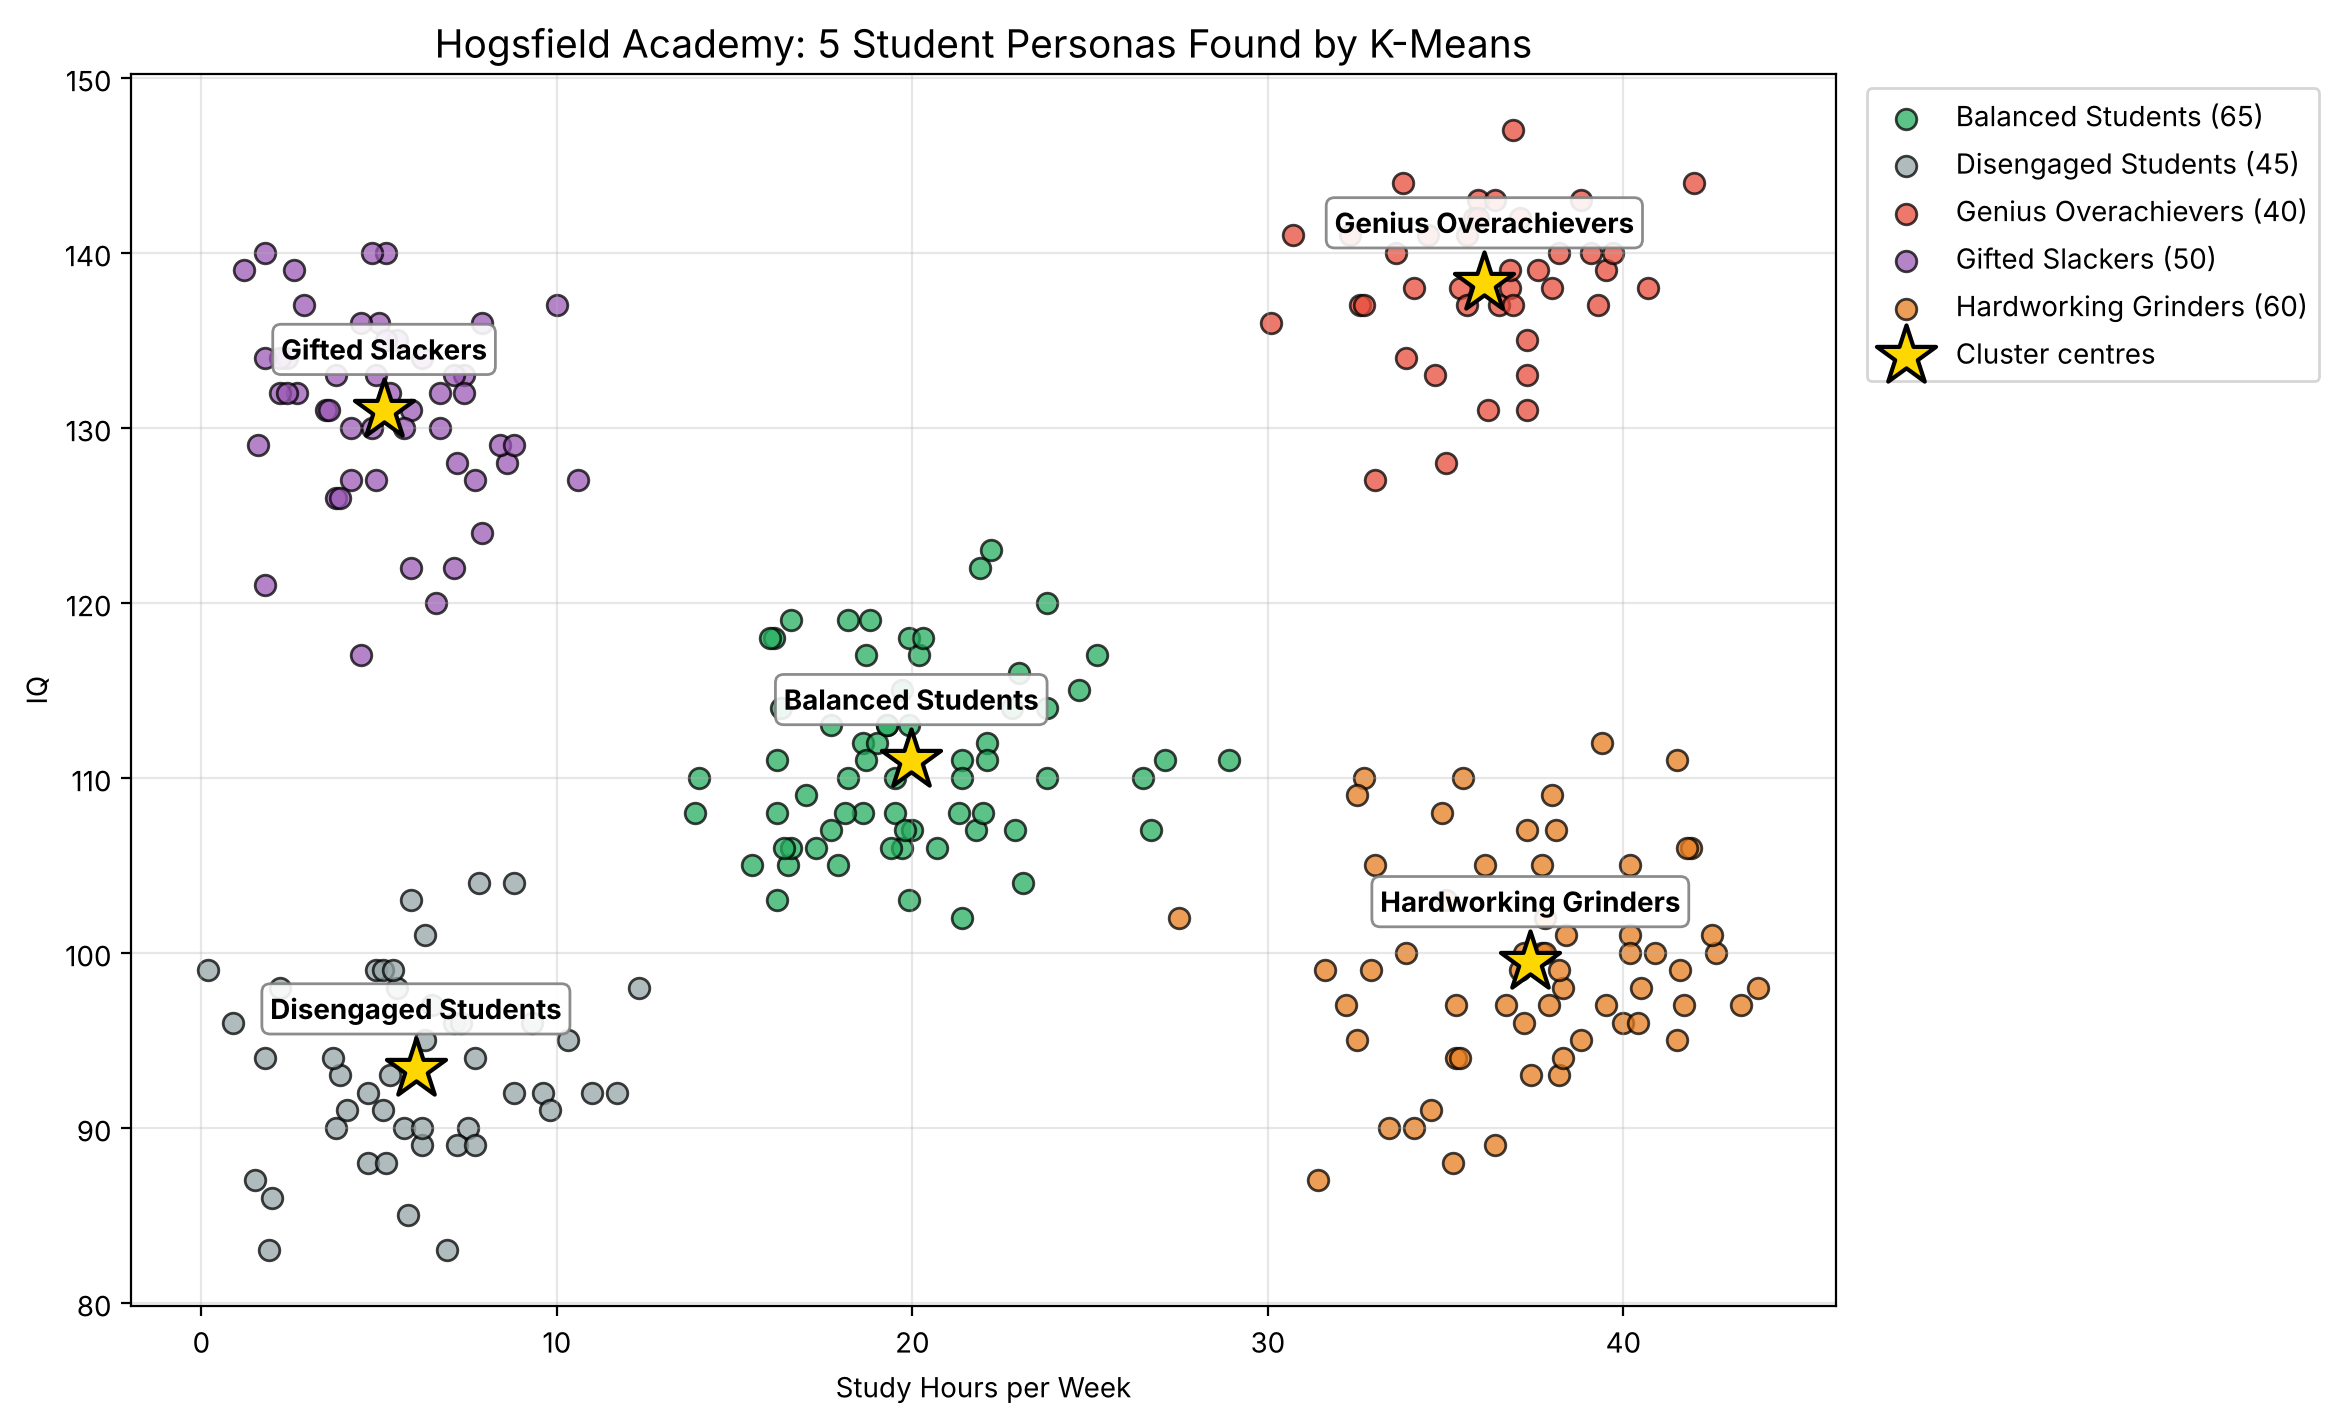

In [11]:
colors = {"Gifted Slackers": "#9b59b6", "Disengaged Students": "#95a5a6",
          "Genius Overachievers": "#e74c3c", "Hardworking Grinders": "#e67e22",
          "Balanced Students": "#27ae60"}

fig, ax = plt.subplots(figsize=(11, 8))
for name, group in df.groupby("Persona"):
    ax.scatter(group["Study_Hours"], group["IQ"], s=55, alpha=0.75,
               color=colors[name], edgecolors="k", label=f"{name} ({len(group)})")

ax.scatter(centroids[:, 0], centroids[:, 1], s=500, c="gold", marker="*",
           edgecolors="black", lw=1.5, zorder=5, label="Cluster centres")

for c, (h, q) in enumerate(centroids):
    ax.annotate(cluster_names[c], (h, q), xytext=(0, 18), textcoords="offset points",
                ha="center", fontsize=10, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.9))

ax.set_title(f"Hogsfield Academy: {best_k} Student Personas Found by K-Means", fontsize=14)
ax.set_xlabel("Study Hours per Week")
ax.set_ylabel("IQ")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=10)
ax.grid(alpha=0.3)
plt.show()

## 10. Persona Report Card

In [12]:
report = (df.groupby("Persona")
            .agg(Students=("Student", "count"),
                 Avg_Study_Hours=("Study_Hours", "mean"),
                 Avg_IQ=("IQ", "mean"),
                 Example_Student=("Student", "first"))
            .round(1)
            .sort_values("Avg_IQ", ascending=False))
report

,Students,Avg_Study_Hours,Avg_IQ,Example_Student
Persona,,,,
Genius Overachievers,40,36.1,138.3,Noor_650
Gifted Slackers,50,5.1,131.0,Omar_596
Balanced Students,65,20.0,111.0,Emma_552
Hardworking Grinders,60,37.4,99.5,Kai_477
Disengaged Students,45,6.0,93.4,Mia_774


## 11. Bonus: Did K-Means Find the Hidden Personas?
We compare the clusters with the hidden `True_Persona` labels that the model never saw.

In [13]:
accuracy = (df["Persona"] == df["True_Persona"]).mean()
print(f"K-Means recovered the true persona for {accuracy:.1%} of students!\n")

pd.crosstab(df["True_Persona"], df["Persona"], rownames=["True"], colnames=["Predicted by K-Means"])

K-Means recovered the true persona for 100.0% of students!



Predicted by K-Means,Balanced Students,Disengaged Students,Genius Overachievers,Gifted Slackers,Hardworking Grinders
True,,,,,
Balanced Students,65,0,0,0,0
Disengaged Students,0,45,0,0,0
Genius Overachievers,0,0,40,0,0
Gifted Slackers,0,0,0,50,0
Hardworking Grinders,0,0,0,0,60


## 🏁 Conclusion
- We built a dataset of **260 students** with two features: **Study Hours** and **IQ**.
- The **Elbow Method** plotted WCSS for K = 1 to 10. The curve bent sharply at **K = 5**.
- K-Means then sorted students into five personas: **Gifted Slackers, Disengaged Students, Balanced Students, Hardworking Grinders and Genius Overachievers**.
- Using only two numbers per student, K-Means put every student back into their correct hidden group.

**Takeaway:** The Elbow Method gives a simple, visual way to choose K. Look for where adding more clusters stops paying off.